# Sleep, Screen Time and Stress Analysis dataset

### Source: Kaggle: https://www.kaggle.com/datasets/jayjoshi37/sleep-screen-time-and-stress-analysis/



---



## Short Description
### This dataset contains 15,000 records and 13 columns on smartphone usage, sleep and stress. Each row is one person, with age, gender, occupation, daily screen time, phone use before bed, sleep duration and quality, caffeine intake, physical activity, notifications per day, stress level and mental fatigue score. The file is a CSV.




---



## Why I selected it
### Smartphones are part of almost everyone’s daily life, and I wanted to explore whether heavy screen time is linked to poorer sleep and higher stress.



---



# Main Questions
- Is higher daily screen time associated with higher stress levels?
- Do people who sleep fewer hours tend to experience higher stress?
- Is using a smartphone before sleeping associated with shorter sleep duration or poorer sleep quality?
- How do caffeine consumption and physical activity relate to sleep and stress?
- Do stress levels vary across occupations?
- Which variables have the strongest relationships with stress levels?
- Do certain occupations, such as doctors, nurses, or other high-pressure professions, tend to have higher stress levels than other occupations?





---



# Insights

1. **Screen Time vs. Stress Levels**: A strong positive correlation is expected, suggesting that high screen time directly relates to increased stress and higher mental fatigue.
2. **The Role of Lifestyle Factors**: I will investigate whether daily habits like caffeine consumption and physical activity can worsen the impact of stress and sleep quality.
3. **Occupational Trends**: I expect to find if high-pressure jobs (e.g., Doctors, Software Engineers) experience higher overall stress levels compared to other occupations, or if stress levels remain relatively uniform across modern professions.

# Setup

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Loading & Structure

Read data and save it into dataframe

In [120]:
df = pd.read_csv("sleep_mobile_stress_dataset_15000.csv")

# Check the header values, 5 values from top

In [121]:
df.head()

,user_id,age,gender,occupation,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes,notifications_received_per_day,mental_fatigue_score
0,1,56,Female,Designer,3.26,86,5.31,7.72,3.49,0,35,119,3.57
1,2,46,Female,Teacher,1.85,32,7.36,9.70,3.01,0,16,299,1.91
2,3,32,Female,Designer,3.04,107,4.50,6.38,5.03,0,17,21,6.05
3,4,25,Male,Software Engineer,9.00,36,6.68,5.53,10.00,0,3,220,9.92
4,5,38,Female,Teacher,3.52,56,7.57,6.69,6.71,4,92,167,5.99


#Check the shape of the data

In [122]:
df.shape

(15000, 13)

# Check the null values and the data type of each column

In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   user_id                           15000 non-null  int64  
 1   age                               15000 non-null  int64  
 2   gender                            15000 non-null  object 
 3   occupation                        15000 non-null  object 
 4   daily_screen_time_hours           15000 non-null  float64
 5   phone_usage_before_sleep_minutes  15000 non-null  int64  
 6   sleep_duration_hours              15000 non-null  float64
 7   sleep_quality_score               15000 non-null  float64
 8   stress_level                      15000 non-null  float64
 9   caffeine_intake_cups              15000 non-null  int64  
 10  physical_activity_minutes         15000 non-null  int64  
 11  notifications_received_per_day    15000 non-null  int64  
 12  ment

# Check the statstics for numerical columns

In [124]:
df.describe()

,user_id,age,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes,notifications_received_per_day,mental_fatigue_score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000
mean,7500.500000,38.488467,5.501528,59.708933,6.509683,6.246362,6.980247,1.99880,59.157133,160.890467,6.873009
std,4330.271354,12.007970,2.600085,34.641858,1.452689,1.713644,2.749382,1.41459,34.525705,80.856902,2.730482
min,1.000000,18.000000,1.000000,0.000000,4.000000,1.000000,1.000000,0.00000,0.000000,20.000000,1.000000
25%,3750.750000,28.000000,3.260000,29.000000,5.260000,5.000000,4.750000,1.00000,29.000000,92.000000,4.700000
50%,7500.500000,38.000000,5.490000,60.000000,6.490000,6.250000,7.380000,2.00000,59.000000,162.000000,7.380000
75%,11250.250000,49.000000,7.760000,90.000000,7.790000,7.500000,10.000000,3.00000,89.000000,231.000000,9.450000
max,15000.000000,59.000000,10.000000,119.000000,9.000000,10.000000,10.000000,4.00000,119.000000,299.000000,10.000000


# Check for total null values in the dataset

In [125]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
occupation,0
daily_screen_time_hours,0
phone_usage_before_sleep_minutes,0
sleep_duration_hours,0
sleep_quality_score,0
stress_level,0
caffeine_intake_cups,0


# Check for duplicate values

In [126]:
df.duplicated().sum()

np.int64(0)

# Check for invalid values in gender column

In [127]:
df['gender'].unique()

array(['Female', 'Male', 'Other'], dtype=object)

# Drop the 'Other' values since it is NOT valid

In [128]:
df = df[df['gender']!='Other']
df['gender'].unique()

array(['Female', 'Male'], dtype=object)

# Check for invalid values in occupation column

In [129]:
df['occupation'].unique()

array(['Designer', 'Teacher', 'Software Engineer', 'Manager', 'Student',
       'Freelancer', 'Doctor', 'Researcher'], dtype=object)

# Rename notifications_received_per_day to notifications_per_day to abberivate

In [130]:
df = df.rename(columns={'notifications_received_per_day': 'notifications_per_day'})
df.columns.tolist()

['user_id',
 'age',
 'gender',
 'occupation',
 'daily_screen_time_hours',
 'phone_usage_before_sleep_minutes',
 'sleep_duration_hours',
 'sleep_quality_score',
 'stress_level',
 'caffeine_intake_cups',
 'physical_activity_minutes',
 'notifications_per_day',
 'mental_fatigue_score']

# Save cleaned dataset to CSV

In [131]:
df.to_csv('sleep_mobile_stress_dataset_15000_cleaned.csv', index=False)

# Exploratory Data Analysis (EDA)

# Ages are uniformly distributed from 18 to 59

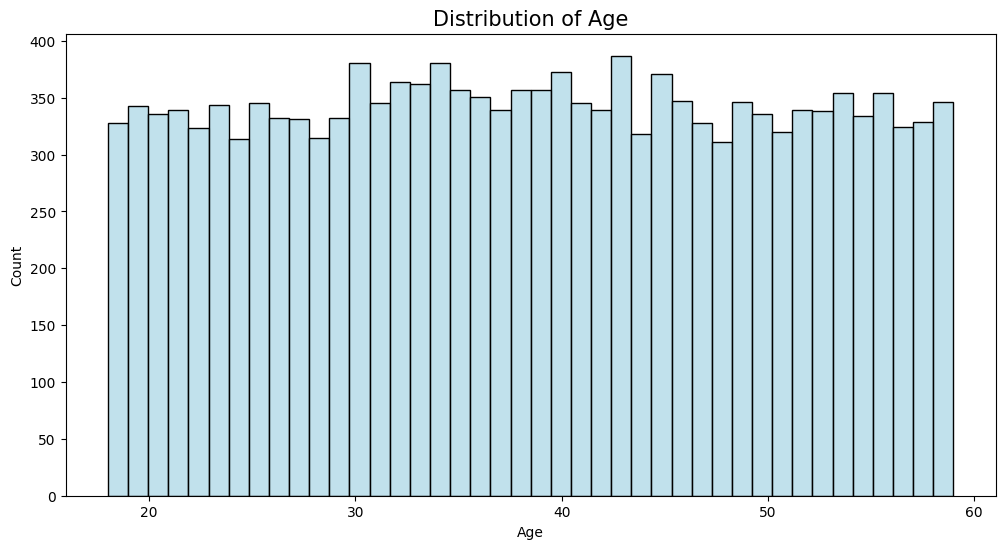

In [156]:
plt.figure(figsize=(12, 6))
sns.histplot(df['age'], bins=42, color='lightblue', edgecolor='black')
plt.title('Distribution of Age', fontsize=15)
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# By looking at the count plot below, we can see that the distribution of gender between 'Male' and 'Female' is balanced

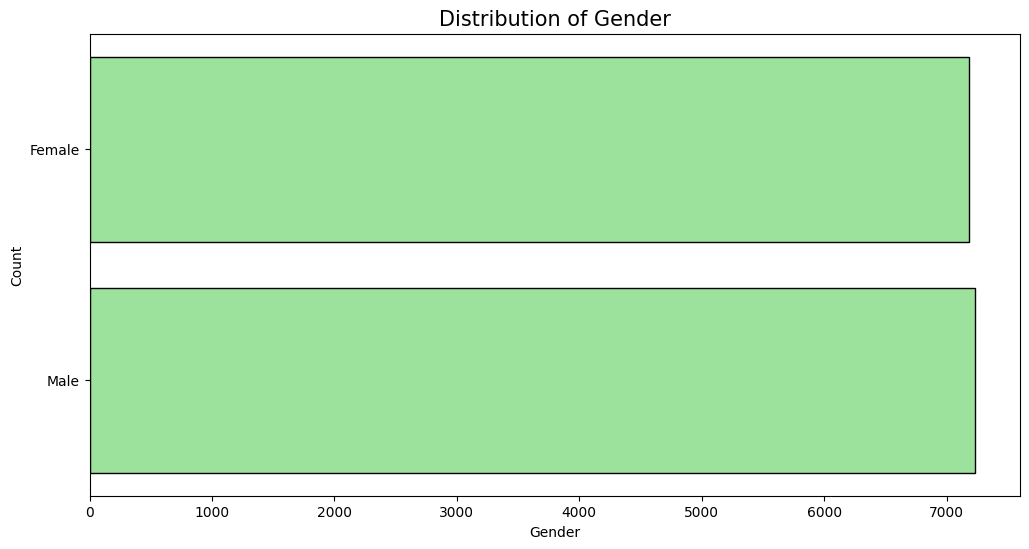

In [133]:
plt.figure(figsize=(12, 6))
sns.countplot(df['gender'], color='lightgreen', edgecolor='black')
plt.title('Distribution of Gender', fontsize=15)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# To verify the balance between the two classes

In [134]:
df['gender'].value_counts()

,count
gender,
Male,7234
Female,7181


# By looking at the count plot below, we can see that the distribution of occupation classes is almost balanced

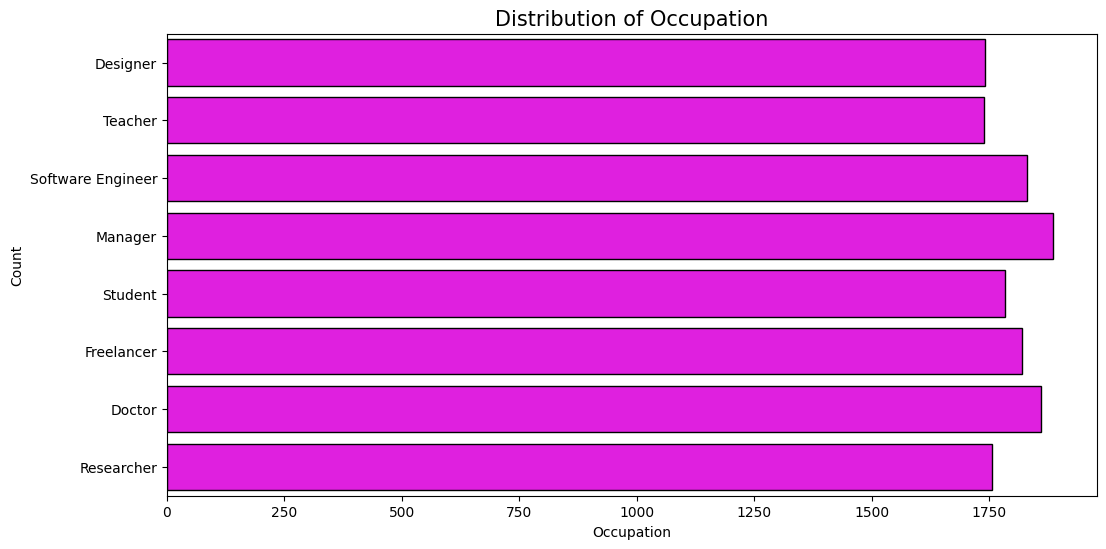

In [135]:
plt.figure(figsize=(12, 6))
sns.countplot(df['occupation'], color='magenta', edgecolor='black')
plt.title('Distribution of Occupation', fontsize=15)
plt.xlabel('Occupation')
plt.ylabel('Count')
plt.show()

# To verify the balance

In [136]:
df['occupation'].value_counts()

,count
occupation,
Manager,1885
Doctor,1860
Software Engineer,1830
Freelancer,1819
Student,1784
Researcher,1757
Designer,1742
Teacher,1738


# Boxplot for all numerical columns to check for outliers

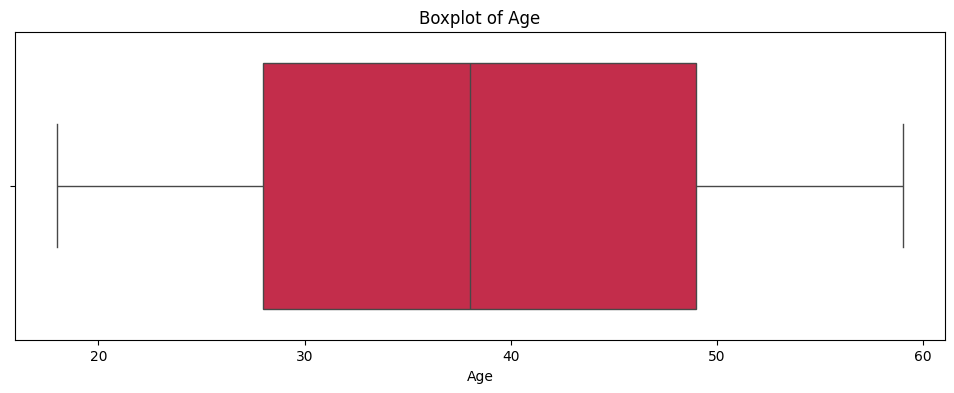

In [137]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['age'],color='crimson')
plt.title('Boxplot of Age')
plt.xlabel('Age')
plt.show()

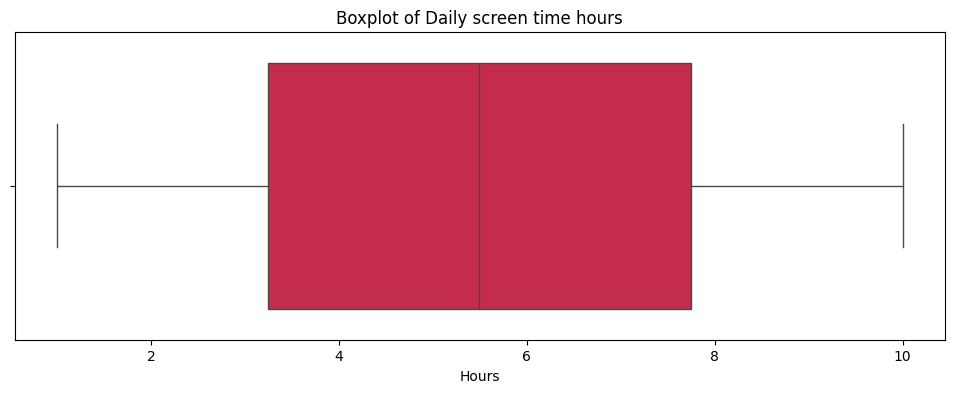

In [138]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['daily_screen_time_hours'],color='crimson')
plt.title('Boxplot of Daily screen time hours')
plt.xlabel('Hours')
plt.show()

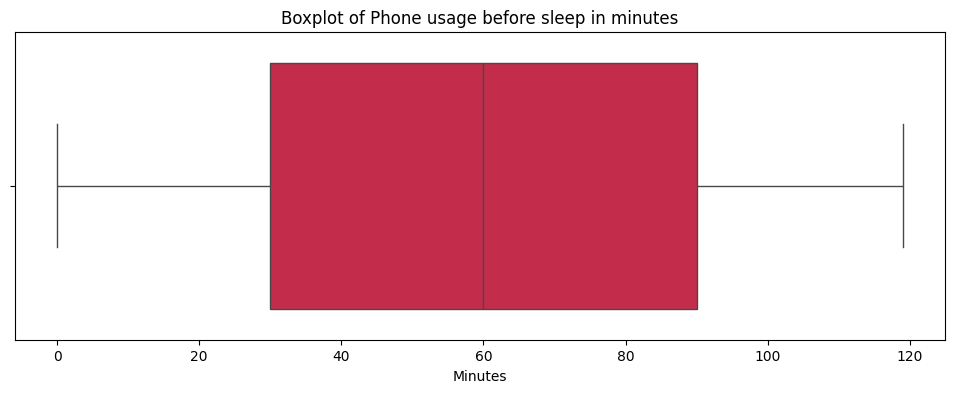

In [139]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['phone_usage_before_sleep_minutes'],color='crimson')
plt.title('Boxplot of Phone usage before sleep in minutes')
plt.xlabel('Minutes')
plt.show()

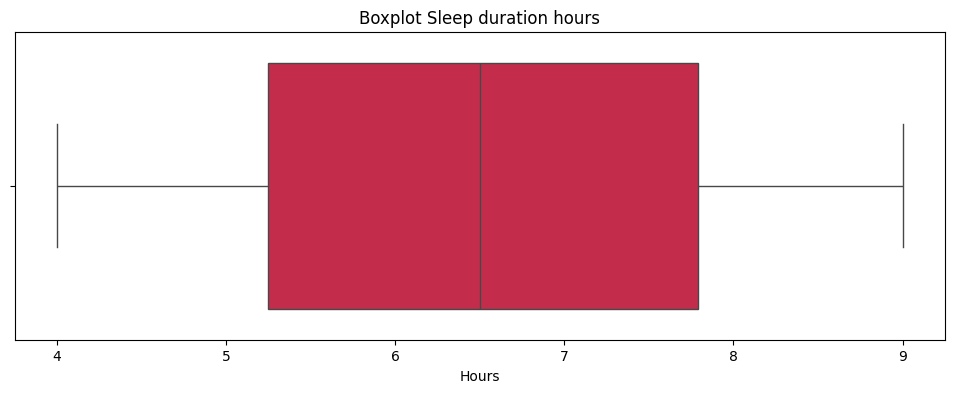

In [140]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['sleep_duration_hours'],color='crimson')
plt.title('Boxplot Sleep duration hours')
plt.xlabel('Hours')
plt.show()

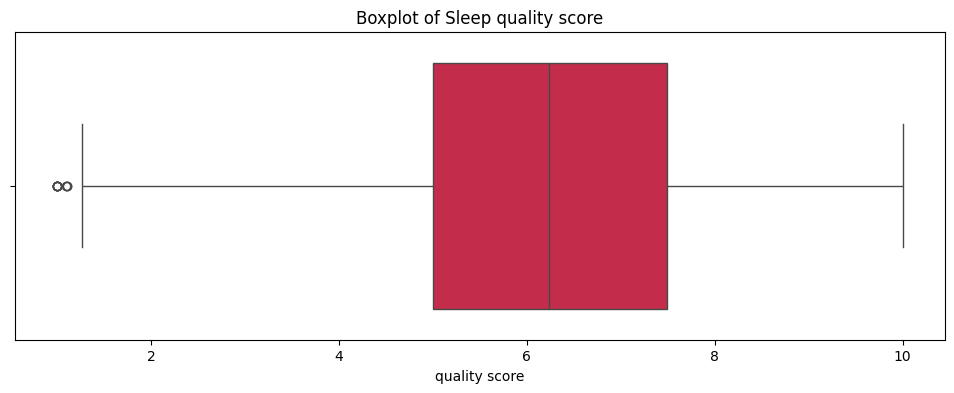

In [141]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['sleep_quality_score'],color='crimson')
plt.title('Boxplot of Sleep quality score')
plt.xlabel('quality score')
plt.show()

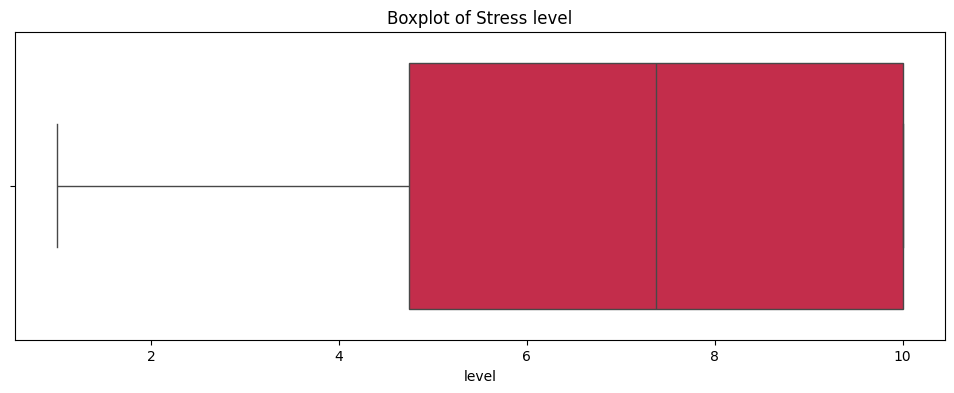

In [142]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['stress_level'],color='crimson')
plt.title('Boxplot of Stress level')
plt.xlabel('level')
plt.show()

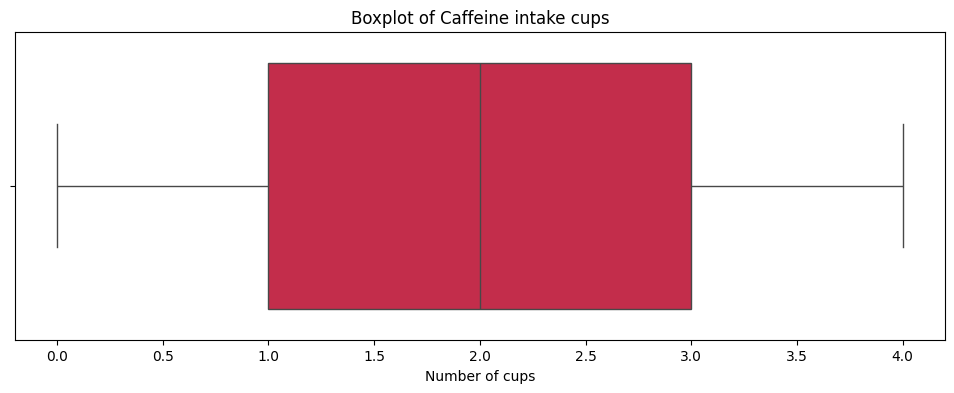

In [143]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['caffeine_intake_cups'],color='crimson')
plt.title('Boxplot of Caffeine intake cups')
plt.xlabel('Number of cups')
plt.show()

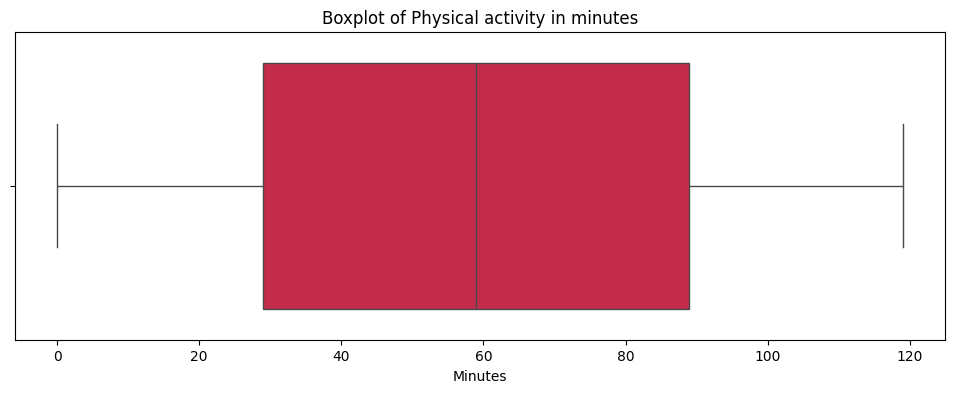

In [144]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['physical_activity_minutes'],color='crimson')
plt.title('Boxplot of Physical activity in minutes')
plt.xlabel('Minutes')
plt.show()

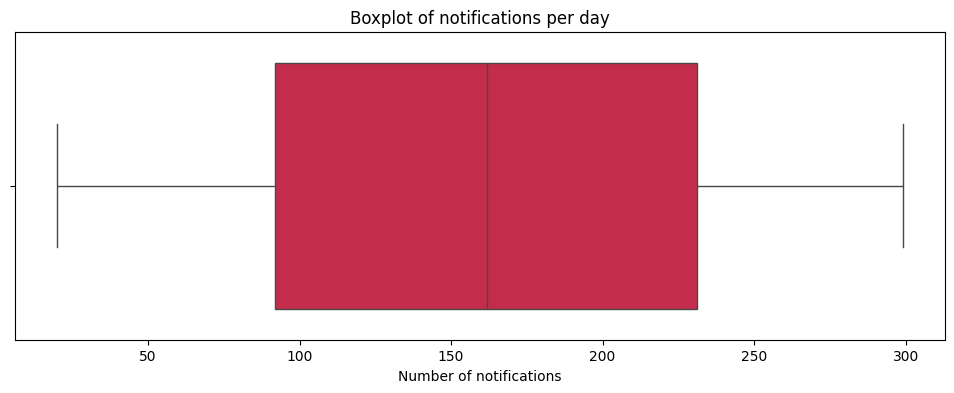

In [145]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['notifications_per_day'],color='crimson')
plt.title('Boxplot of notifications per day')
plt.xlabel('Number of notifications')
plt.show()

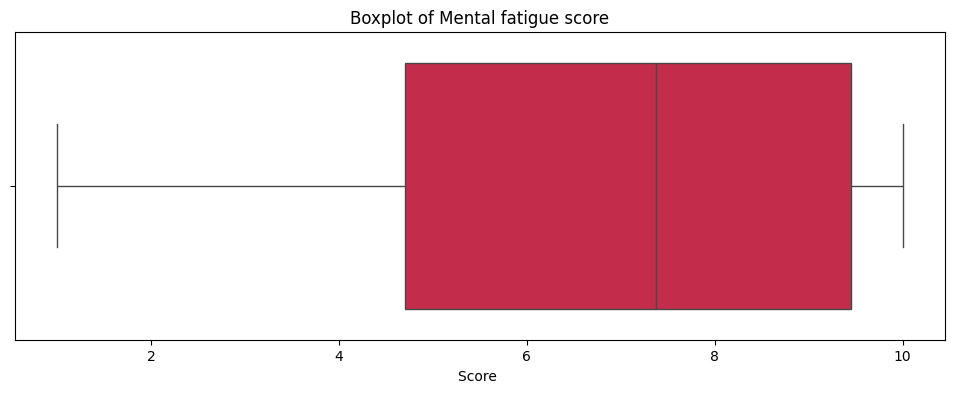

In [146]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=df,x=df['mental_fatigue_score'],color='crimson')
plt.title('Boxplot of Mental fatigue score')
plt.xlabel('Score ')
plt.show()

# Looking at the boxplots above we can now know that'sleep_quality_score' column has some outliers where we can explore if they are valid or not

In [147]:
Q1 = np.quantile(df['sleep_quality_score'],0.25)
Q3 = np.quantile(df['sleep_quality_score'],0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['sleep_quality_score'] < lower_bound) | (df['sleep_quality_score'] > upper_bound)]

print("Q1: ",Q1)
print("Q3: ",Q3)
print("IQR: ",IQR)
print("Lower bound: ",lower_bound.round(2))
print("Upper bound: ",upper_bound.round(2))
print("Number of outliers: ",len(outliers))
print("-"*50)
print("Outliers:\n",outliers)

# In this case, I am assuming that those outliers are valid and should not be removed

Q1:  5.0
Q3:  7.49
IQR:  2.49
Lower bound:  1.26
Upper bound:  11.23
Number of outliers:  9
--------------------------------------------------
Outliers:
        user_id  age  gender  occupation  daily_screen_time_hours  \
253        254   37    Male     Manager                     9.63   
519        520   26  Female     Student                     9.09   
1434      1435   20  Female    Designer                     9.97   
2266      2267   45  Female     Student                     9.27   
5379      5380   29  Female  Freelancer                     9.64   
7411      7412   18  Female  Freelancer                     9.01   
9519      9520   23    Male     Teacher                     9.60   
9592      9593   41  Female  Researcher                     9.80   
11011    11012   18    Male      Doctor                     9.72   

       phone_usage_before_sleep_minutes  sleep_duration_hours  \
253                                 114                  4.64   
519                                

#Q1: Is higher daily screen time associated with higher stress levels?
#Answer: Yes, by looking at the scatter plot, we can see that higher screen time is associated with higher stress level

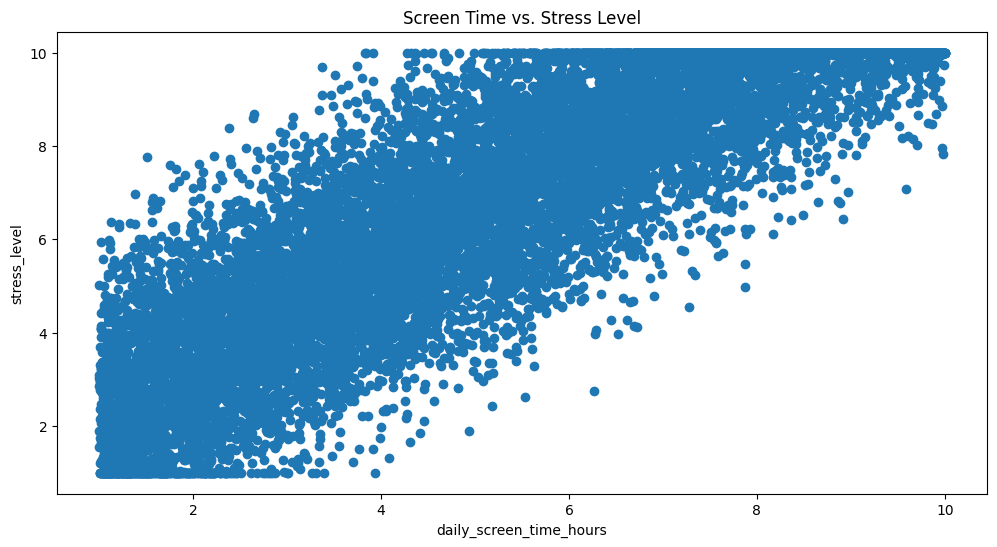

In [148]:
plt.figure(figsize=(12,6))
plt.scatter(x=df['daily_screen_time_hours'],y=df['stress_level'])
plt.xlabel("daily_screen_time_hours")
plt.ylabel("stress_level")
plt.title('Screen Time vs. Stress Level')
plt.show()

# Q2: Do people who sleep fewer hours tend to experience higher stress?

# Answer: No it is not a must, based on the scatter below, people who sleep less may have high stress and vice versa

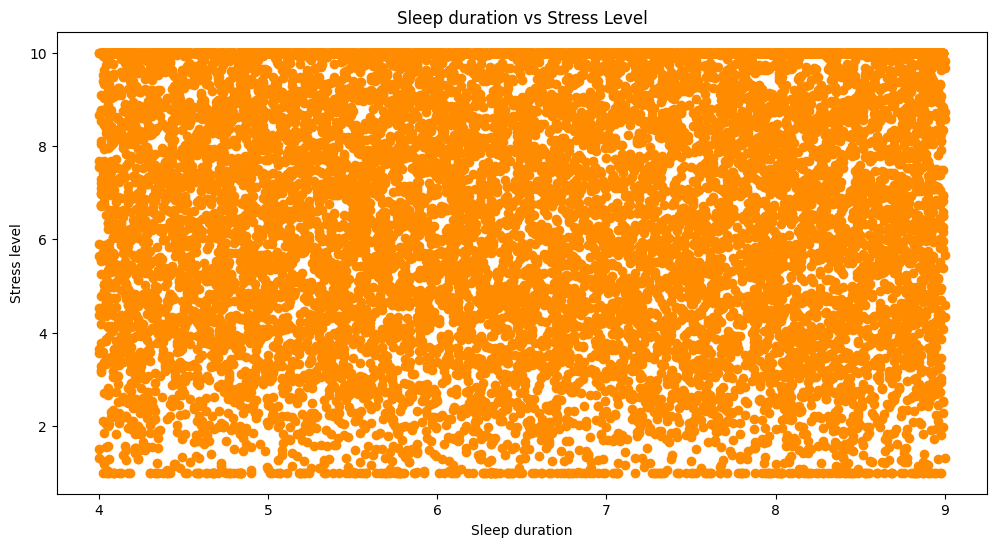

In [149]:
plt.figure(figsize=(12,6))
plt.scatter(x=df['sleep_duration_hours'],y=df['stress_level'],color='darkorange')
plt.xlabel("Sleep duration")
plt.ylabel("Stress level")
plt.title('Sleep duration vs Stress Level')
plt.show()

# Q3: Is using a smartphone before sleeping associated with shorter sleep duration or poorer sleep quality?

# Answer: No, using smartphone before sleep does not affect the sleep duration or the quality that much, some people used for 120 minutes and got good sleep quality or duration


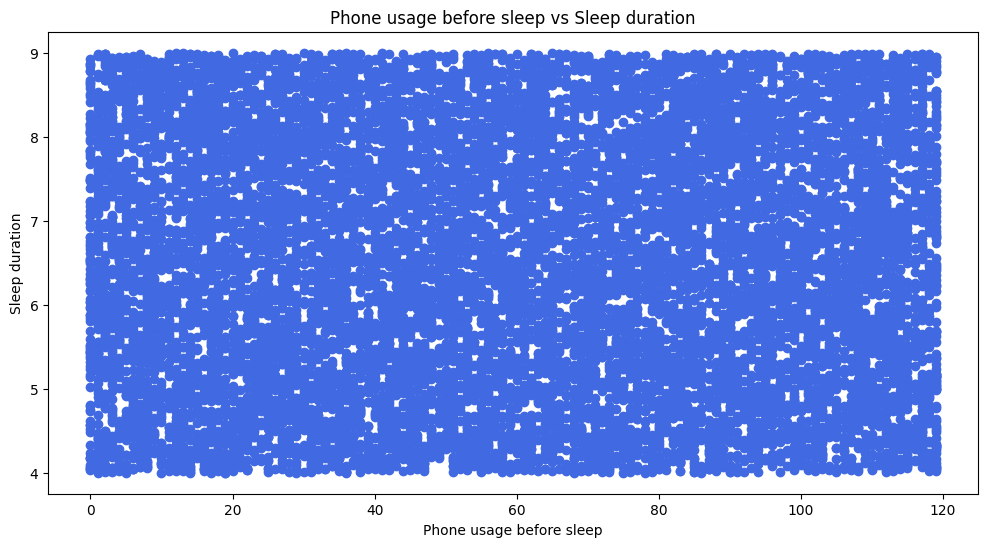

In [150]:
plt.figure(figsize=(12,6))
plt.scatter(x=df['phone_usage_before_sleep_minutes'],y=df['sleep_duration_hours'],color='royalblue')
plt.xlabel("Phone usage before sleep")
plt.ylabel("Sleep duration")
plt.title('Phone usage before sleep vs Sleep duration')
plt.show()

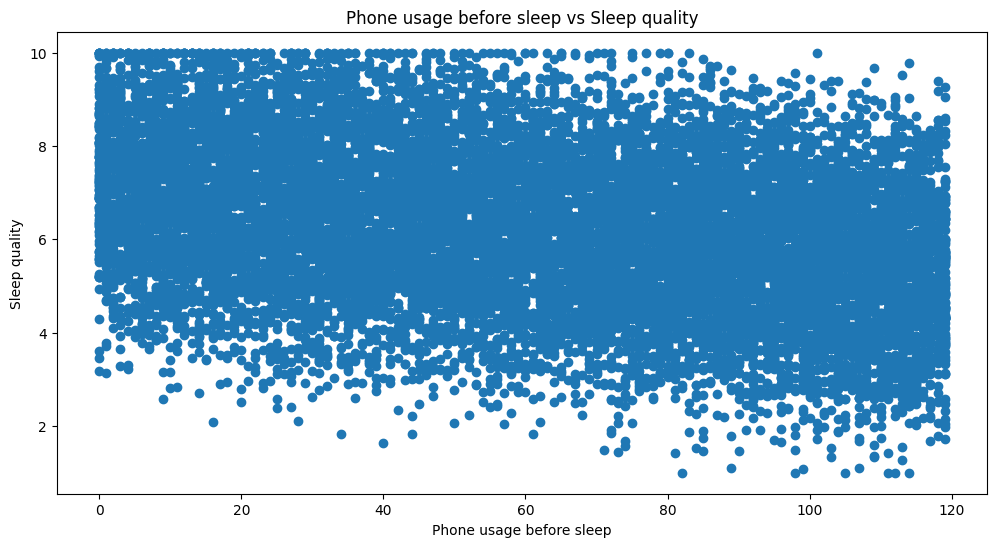

In [151]:
plt.figure(figsize=(12,6))
plt.scatter(x=df['phone_usage_before_sleep_minutes'],y=df['sleep_quality_score'])
plt.xlabel("Phone usage before sleep")
plt.ylabel("Sleep quality")
plt.title('Phone usage before sleep vs Sleep quality')
plt.show()

# Q4: How do caffeine consumption and physical activity relate to sleep and stress?

# Answer: Based on the heatmap below
- There is a negative correlation between sleep quality and stress level, meaning the less quailty of sleep a person have, the higher stress will get
- There is a positive correlation between mental fatigue and stress level, meaning higher stress is associated with mental fatigue
- Caffeine intake has no relation with sleep or stress
- Physical activity has no relation with sleep or stress


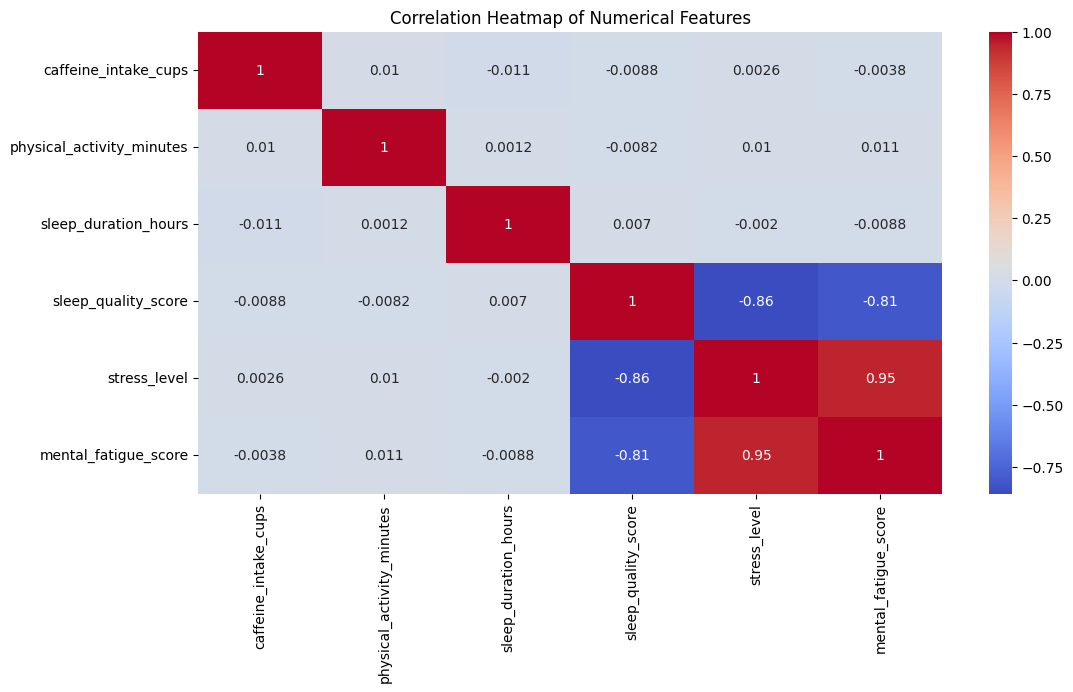

In [152]:
columns = ['caffeine_intake_cups', 'physical_activity_minutes', 'sleep_duration_hours', 'sleep_quality_score', 'stress_level', 'mental_fatigue_score']
correlation_matrix = df[columns].corr()
correlation_matrix

plt.figure(figsize=(12, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

Do certain occupations, such as doctors, nurses, or other high-pressure professions, tend to have higher stress levels than other occupations?

# Q5: Do stress levels vary across occupations?

#Answer: Not that variation, however we can see that Students have the most average stress level between all occupations

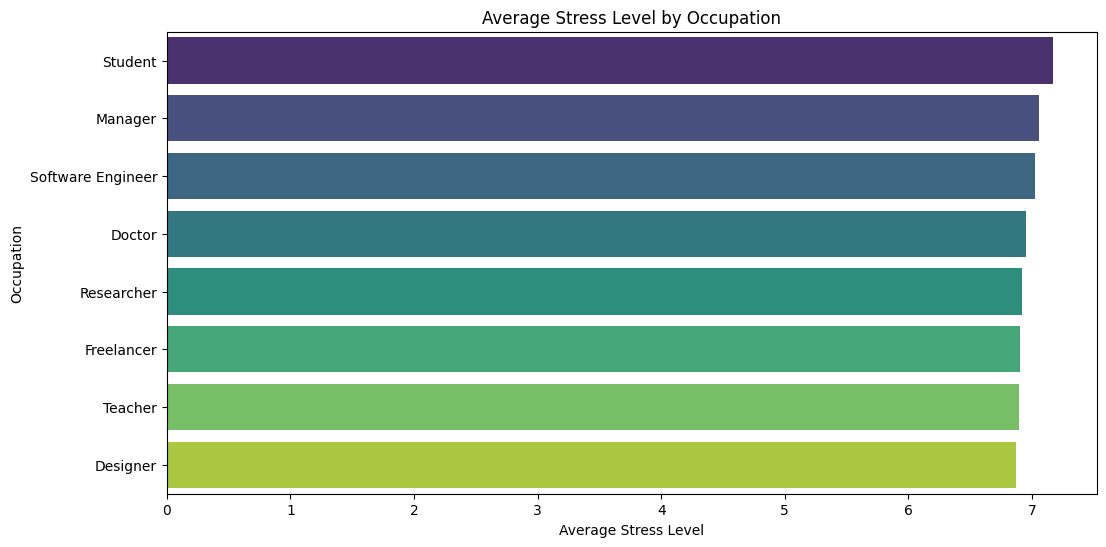

In [153]:
occ_stress = df.groupby('occupation')['stress_level'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=occ_stress, x='stress_level', y='occupation', palette='viridis', hue='occupation')
plt.title('Average Stress Level by Occupation')
plt.xlabel('Average Stress Level')
plt.ylabel('Occupation')
plt.show()

#Q6: Which variables have the strongest relationships with stress levels?

#Answer: 'mental_fatigue_score' has the strongest relationship with stress level

In [154]:
numerical_cols = df.select_dtypes(include=[np.number]).columns
stress_correlations = df[numerical_cols].corr()['stress_level'].sort_values(ascending=False).reset_index()
stress_correlations.columns = ['Feature', 'Correlation']

stress_correlations[1:]

,Feature,Correlation
1,mental_fatigue_score,0.948580
2,daily_screen_time_hours,0.878886
3,phone_usage_before_sleep_minutes,0.155571
4,user_id,0.010456
5,physical_activity_minutes,0.010289
6,caffeine_intake_cups,0.002594
7,age,0.000990
8,sleep_duration_hours,-0.001994
9,notifications_per_day,-0.004872
10,sleep_quality_score,-0.858093


# Q7: Do certain occupations, such as doctors, nurses, or other high-pressure professions, tend to have higher stress levels than other occupations?

#Answer: No, based on the barplot below, high-pressure jobs is not associated with higher stress. The stress for all professions is close

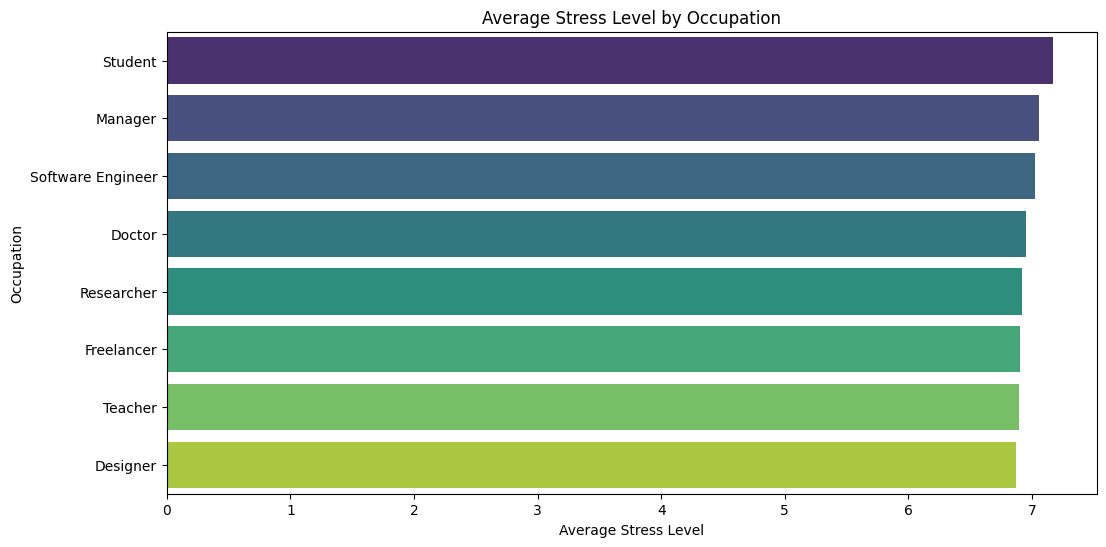

In [155]:
occ_stress = df.groupby('occupation')['stress_level'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=occ_stress, x='stress_level', y='occupation', palette='viridis', hue='occupation')
plt.title('Average Stress Level by Occupation')
plt.xlabel('Average Stress Level')
plt.ylabel('Occupation')
plt.show()

# Insights Summary
# Key Patterns Discovered
- Ages are uniformly distributed between 18 and 59, while gender and occupations are highly balanced.
- Occupational Stress: Stress levels remain relatively consistent across different jobs. Students exhibit the highest average stress levels, whereas designers show the lowest, though the margin is small.
# Interesting Relationships
- Stress & Mental Fatigue: There is strong positive correlation (~0.95) between stress levels and mental fatigue.
- Screen Time & Stress: Daily screen time is strongly positively correlated (~0.88) with stress, showing that more time on devices is closely linked to higher stress.
- Sleep Quality vs. Stress: Sleep quality has a strong negative correlation (-0.86) with stress. Better sleep directly relates to lower stress levels.
- Caffeine & Physical Activity: Caffeine intake and physical activity show virtually no linear correlation (< 0.01) with stress or sleep duration in this dataset.

# Outliers
- We identified 9 key outliers in sleep_quality_score (values near 1.0 associated with maximum stress of 10.0 and highest mental fatigue of 10.0)

# Key takeaways
- To reduce stress and mental fatigue, reducing daily screen time and improving sleep quality appear to be much more impactful than adjusting caffeine intake or physical activity levels based on this dataset.